In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

In [2]:
face_value = 100000
coupon_rate = 0.12
years = 5
frequency = 2

market_price = 96000

In [3]:
def bond_price(face_value, coupon_rate, ytm, years, frequency=2):
    coupon = face_value * coupon_rate / frequency
    periods = int(years * frequency)

    price = 0

    for t in range(1, periods + 1):
        price += coupon / (1 + ytm / frequency) ** t

    price += face_value / (1 + ytm / frequency) ** periods

    return price


In [4]:
def calculate_ytm(market_price, face_value, coupon_rate, years, frequency=2):

    def price_difference(yield_guess):
        return bond_price(
            face_value, coupon_rate, yield_guess, years, frequency
        ) - market_price

    return brentq(price_difference, 0.001, 1.0)


ytm = calculate_ytm(
    market_price, face_value, coupon_rate, years, frequency
)

print(f"Yield to Maturity: {ytm:.2%}")


Yield to Maturity: 13.12%


In [5]:
def modified_duration(face_value, coupon_rate, ytm, years, frequency=2):
    coupon = face_value * coupon_rate / frequency
    periods = int(years * frequency)

    weighted_pv = 0

    for t in range(1, periods + 1):
        cash_flow = coupon

        if t == periods:
            cash_flow += face_value

        pv = cash_flow / (1 + ytm / frequency) ** t
        time_in_years = t / frequency

        weighted_pv += time_in_years * pv

    price = bond_price(
        face_value, coupon_rate, ytm, years, frequency
    )

    macaulay_duration = weighted_pv / price
    mod_duration = macaulay_duration / (1 + ytm / frequency)

    return mod_duration


duration = modified_duration(
    face_value, coupon_rate, ytm, years, frequency
)

print(f"Modified Duration: {duration:.3f}")


Modified Duration: 3.637


In [6]:
def calculate_dv01(face_value, coupon_rate, ytm, years, frequency=2):

    yield_change = 0.0001

    price_up = bond_price(
        face_value, coupon_rate, ytm + yield_change, years, frequency
    )

    price_down = bond_price(
        face_value, coupon_rate, ytm - yield_change, years, frequency
    )

    dv01 = (price_down - price_up) / 2

    return dv01


dv01 = calculate_dv01(
    face_value, coupon_rate, ytm, years, frequency
)

print(f"DV01: KES {dv01:.2f} per basis point")


DV01: KES 34.91 per basis point


In [7]:
yield_changes = [-0.02, -0.01, -0.005, 0, 0.005, 0.01, 0.02]

print("Yield Change | New Price | Profit/Loss")

for change in yield_changes:
    new_yield = ytm + change

    new_price = bond_price(
        face_value, coupon_rate, new_yield, years, frequency
    )

    pnl = new_price - market_price

    print(
        f"{change * 10000:+6.0f} bps | "
        f"KES {new_price:,.2f} | "
        f"KES {pnl:+,.2f}"
    )


Yield Change | New Price | Profit/Loss
  -200 bps | KES 103,322.93 | KES +7,322.93
  -100 bps | KES 99,574.81 | KES +3,574.81
   -50 bps | KES 97,766.32 | KES +1,766.32
    +0 bps | KES 96,000.00 | KES -0.00
   +50 bps | KES 94,274.72 | KES -1,725.28
  +100 bps | KES 92,589.41 | KES -3,410.59
  +200 bps | KES 89,334.48 | KES -6,665.52


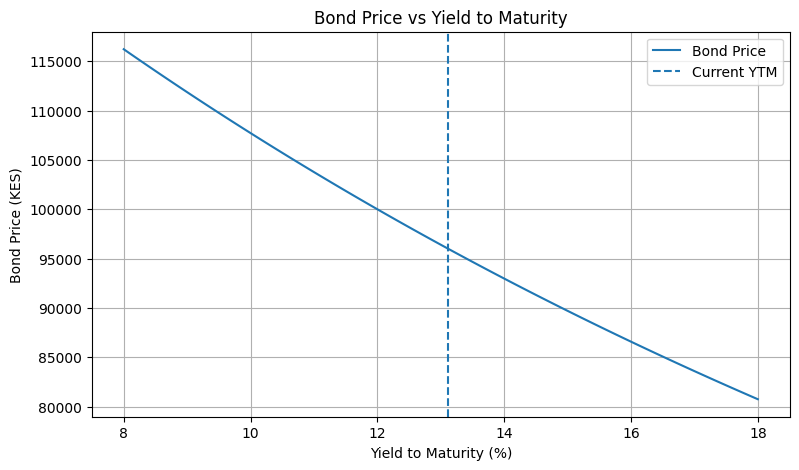

In [8]:
yields = np.linspace(0.08, 0.18, 101)

prices = []

for y in yields:
    price = bond_price(
        face_value, coupon_rate, y, years, frequency
    )
    prices.append(price)

plt.figure(figsize=(9, 5))

plt.plot(yields * 100, prices, label="Bond Price")

plt.axvline(
    ytm * 100,
    linestyle="--",
    label="Current YTM"
)

plt.xlabel("Yield to Maturity (%)")
plt.ylabel("Bond Price (KES)")
plt.title("Bond Price vs Yield to Maturity")

plt.grid(True)
plt.legend()
plt.show()


In [9]:
print("BOND PRICING & INTEREST RATE RISK ANALYSIS")
print("------------------------------------------")

print(f"Face Value:        KES {face_value:,.2f}")
print(f"Market Price:      KES {market_price:,.2f}")
print(f"Coupon Rate:       {coupon_rate:.2%}")
print(f"Years to Maturity: {years}")
print(f"Yield to Maturity: {ytm:.2%}")
print(f"Modified Duration: {duration:.3f}")
print(f"DV01:              KES {dv01:.2f}")


BOND PRICING & INTEREST RATE RISK ANALYSIS
------------------------------------------
Face Value:        KES 100,000.00
Market Price:      KES 96,000.00
Coupon Rate:       12.00%
Years to Maturity: 5
Yield to Maturity: 13.12%
Modified Duration: 3.637
DV01:              KES 34.91
